In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
GPU available: False


In [2]:
from torchvision import datasets, transforms

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download and load the training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download and load the test dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

100.0%
100.0%
100.0%
100.0%

Training images: 60000
Test images: 10000


In [3]:
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

Training images: 60000
Test images: 10000
Image shape: torch.Size([1, 28, 28])
Label: 5


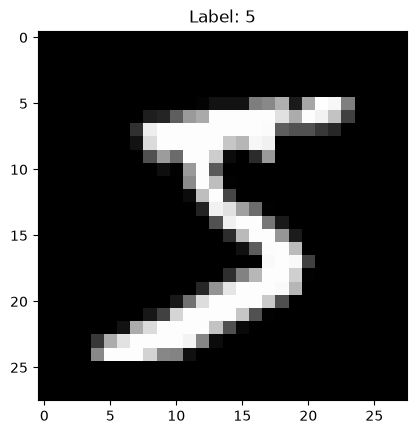

In [60]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.show()

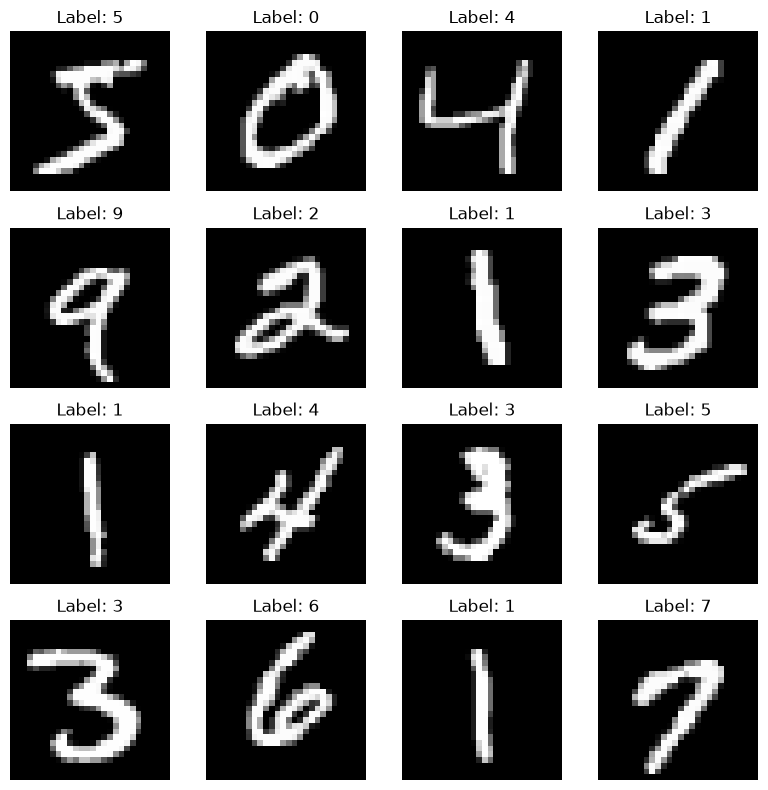

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
from torch.utils.data import DataLoader

# Create batches of images for training
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

# Check the shape of one batch
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])


In [7]:
import torch
import torch.nn as nn

class MNISTModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MNISTModel()

print(model)

MNISTModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [8]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Output shape:", outputs.shape)
print("Actual label:", labels[0].item())
print("Predicted label:", outputs[0].argmax().item())

Output shape: torch.Size([64, 10])
Actual label: 6
Predicted label: 7


In [9]:
import torch.nn as nn

# Measures how wrong the model's predictions are
loss_function = nn.CrossEntropyLoss()

# Updates the model's weights to improve predictions
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Loss function and optimizer ready!")

Loss function and optimizer ready!


In [10]:
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_function(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )

Epoch 1/5, Loss: 0.3450
Epoch 2/5, Loss: 0.1604
Epoch 3/5, Loss: 0.1117
Epoch 4/5, Loss: 0.0839
Epoch 5/5, Loss: 0.0668


In [11]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Test accuracy: {accuracy:.2f}%")

Test accuracy: 97.58%


In [ ]:
import matplotlib.pyplot as plt

model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    predictions = model(images).argmax(dim=1)

wrong = (predictions != labels).nonzero()

if len(wrong) > 0:
    i = wrong[0].item()

    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(
        f"Actual: {labels[i].item()}, "
        f"Predicted: {predictions[i].item()}"
    )
    plt.axis("off")
    plt.show()
else:
    print("No incorrect predictions in this batch")

No incorrect predictions in this batch


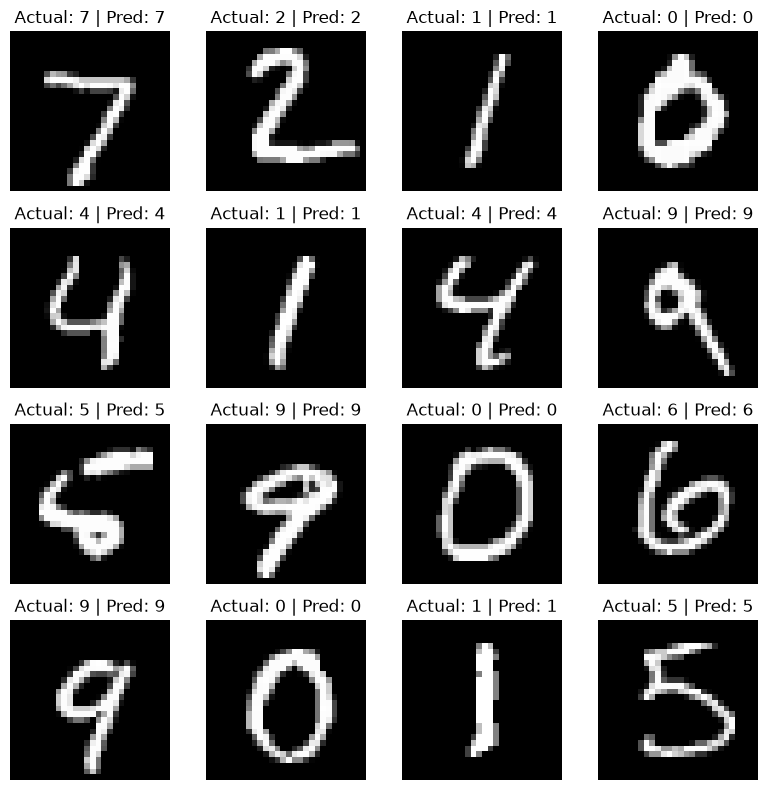

In [14]:
import matplotlib.pyplot as plt
import torch

model.eval()

images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    actual = labels[i].item()
    predicted = predictions[i].item()

    ax.set_title(f"Actual: {actual} | Pred: {predicted}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Correct predictions: {correct}/{total}")
print(f"Test accuracy: {accuracy:.2f}%")

Correct predictions: 9758/10000
Test accuracy: 97.58%


ONE IMAGE
Shape: torch.Size([1, 28, 28])
Data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Correct label: 5

MINI-BATCH
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Flattened batch shape: torch.Size([64, 784])


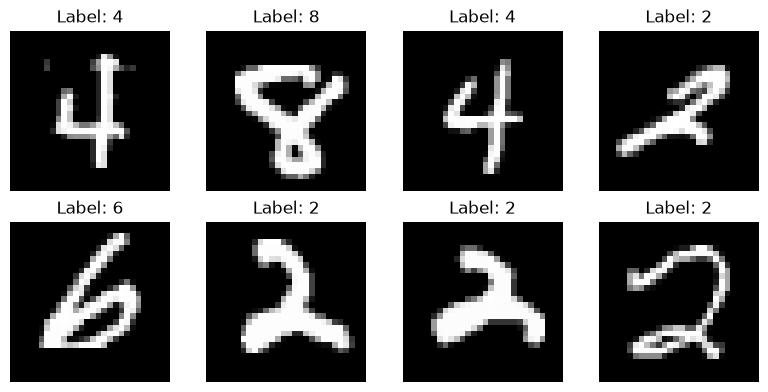


Test accuracy: 97.58%
Correct: 9758/10000


In [ ]:
import torch
import matplotlib.pyplot as plt

image, label = train_dataset[0]

print("ONE IMAGE")
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())
print("Correct label:", label)

images, labels = next(iter(train_loader))

print("\nMINI-BATCH")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

flattened = images.flatten(start_dim=1)
print("Flattened batch shape:", flattened.shape)

fig, axes = plt.subplots(2, 4, figsize=(8, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"\nTest accuracy: {100 * correct / total:.2f}%")
print(f"Correct: {correct}/{total}")

In [17]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

torch.manual_seed(42)

experiment_train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

def make_model(hidden_neurons):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, hidden_neurons),
        nn.ReLU(),
        nn.Linear(hidden_neurons, 10)
    )

def train_model(model, loader, epochs=5):
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(loader)
        history.append(average_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Loss: {average_loss:.4f}"
        )

    return history

def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

torch.manual_seed(42)
baseline_model = make_model(128)

print("Training baseline: 128 hidden neurons")
baseline_history = train_model(
    baseline_model, experiment_train_loader
)
baseline_accuracy = evaluate_model(
    baseline_model, test_loader
)

torch.manual_seed(42)
larger_model = make_model(256)

print("\nTraining experiment: 256 hidden neurons")
larger_history = train_model(
    larger_model, experiment_train_loader
)
larger_accuracy = evaluate_model(
    larger_model, test_loader
)

print("\n--- FINAL COMPARISON ---")
print(f"128 neurons: {baseline_accuracy:.2f}% accuracy")
print(f"256 neurons: {larger_accuracy:.2f}% accuracy")
print(
    f"Accuracy difference: "
    f"{larger_accuracy - baseline_accuracy:+.2f} "
    "percentage points"
)
print(f"128-neuron final loss: {baseline_history[-1]:.4f}")
print(f"256-neuron final loss: {larger_history[-1]:.4f}")


Training baseline: 128 hidden neurons
Epoch 1/5 | Loss: 0.3447
Epoch 2/5 | Loss: 0.1580
Epoch 3/5 | Loss: 0.1082
Epoch 4/5 | Loss: 0.0811
Epoch 5/5 | Loss: 0.0641

Training experiment: 256 hidden neurons
Epoch 1/5 | Loss: 0.3024
Epoch 2/5 | Loss: 0.1280
Epoch 3/5 | Loss: 0.0848
Epoch 4/5 | Loss: 0.0605
Epoch 5/5 | Loss: 0.0450

--- FINAL COMPARISON ---
128 neurons: 97.46% accuracy
256 neurons: 97.57% accuracy
Accuracy difference: +0.11 percentage points
128-neuron final loss: 0.0641
256-neuron final loss: 0.0450


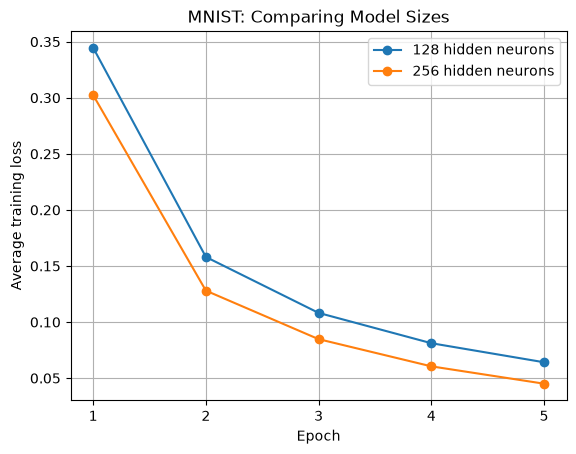

In [ ]:
import matplotlib.pyplot as plt

plt.plot(
    range(1, 6),
    baseline_history,
    marker="o",
    label="128 hidden neurons"
)

plt.plot(
    range(1, 6),
    larger_history,
    marker="o",
    label="256 hidden neurons"
)

plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("MNIST: Comparing Model Sizes")s
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

In [19]:
image, label = train_dataset[0]

print("One image shape:", image.shape)
print("Image data type:", image.dtype)
print("Label:", label)

images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Batch labels shape:", labels.shape)

One image shape: torch.Size([1, 28, 28])
Image data type: torch.float32
Label: 5
Batch shape: torch.Size([64, 1, 28, 28])
Batch labels shape: torch.Size([64])


In [20]:
import torch
import torch.nn as nn

class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.fc2(x)

        return x


cnn_model = MNISTCNN()

print(cnn_model)

MNISTCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [21]:
images, labels = next(iter(train_loader))

cnn_model.eval()

with torch.no_grad():
    x = cnn_model.conv1(images)
    print("After conv1:", x.shape)

    x = cnn_model.relu1(x)
    x = cnn_model.pool1(x)
    print("After pool1:", x.shape)

    x = cnn_model.conv2(x)
    print("After conv2:", x.shape)

    x = cnn_model.relu2(x)
    x = cnn_model.pool2(x)
    print("After pool2:", x.shape)

    x = cnn_model.flatten(x)
    print("After flatten:", x.shape)

    x = cnn_model.fc1(x)
    print("After fc1:", x.shape)

    x = cnn_model.relu3(x)
    x = cnn_model.fc2(x)
    print("Final output:", x.shape)

After conv1: torch.Size([64, 16, 28, 28])
After pool1: torch.Size([64, 16, 14, 14])
After conv2: torch.Size([64, 32, 14, 14])
After pool2: torch.Size([64, 32, 7, 7])
After flatten: torch.Size([64, 1568])
After fc1: torch.Size([64, 128])
Final output: torch.Size([64, 10])


In [22]:
import torch
import torch.nn as nn

# Set up a fresh model for training
cnn_model = MNISTCNN()

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

epochs = 5
cnn_train_losses = []

for epoch in range(epochs):
    cnn_model.train()
    total_loss = 0

    for images, labels in train_loader:
        # Forward pass
        outputs = cnn_model(images)

        # Calculate prediction error
        loss = loss_function(outputs, labels)

        # Backpropagation and weight update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    cnn_train_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Training loss: {average_loss:.4f}"
    )

Epoch 1/5 | Training loss: 0.2229
Epoch 2/5 | Training loss: 0.0641
Epoch 3/5 | Training loss: 0.0452
Epoch 4/5 | Training loss: 0.0350
Epoch 5/5 | Training loss: 0.0281


In [23]:
cnn_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

cnn_accuracy = 100 * correct / total

print(f"Correct predictions: {correct}/{total}")
print(f"CNN test accuracy: {cnn_accuracy:.2f}%")

Correct predictions: 9893/10000
CNN test accuracy: 98.93%


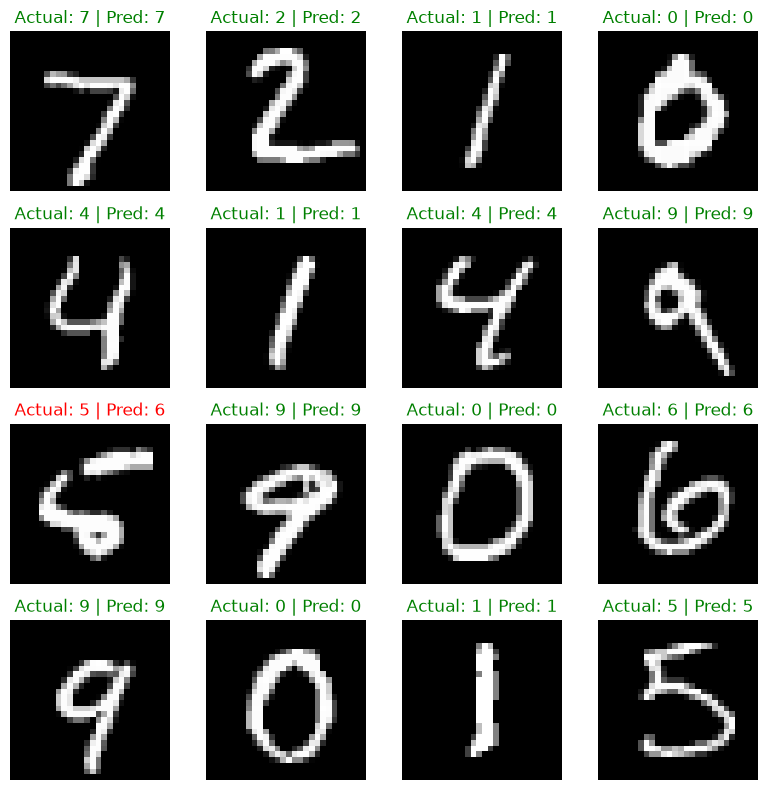

In [24]:
import matplotlib.pyplot as plt

cnn_model.eval()
images, labels = next(iter(test_loader))

with torch.no_grad():
    predictions = cnn_model(images).argmax(dim=1)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    actual = labels[i].item()
    predicted = predictions[i].item()

    color = "green" if actual == predicted else "red"
    ax.set_title(
        f"Actual: {actual} | Pred: {predicted}",
        color=color
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

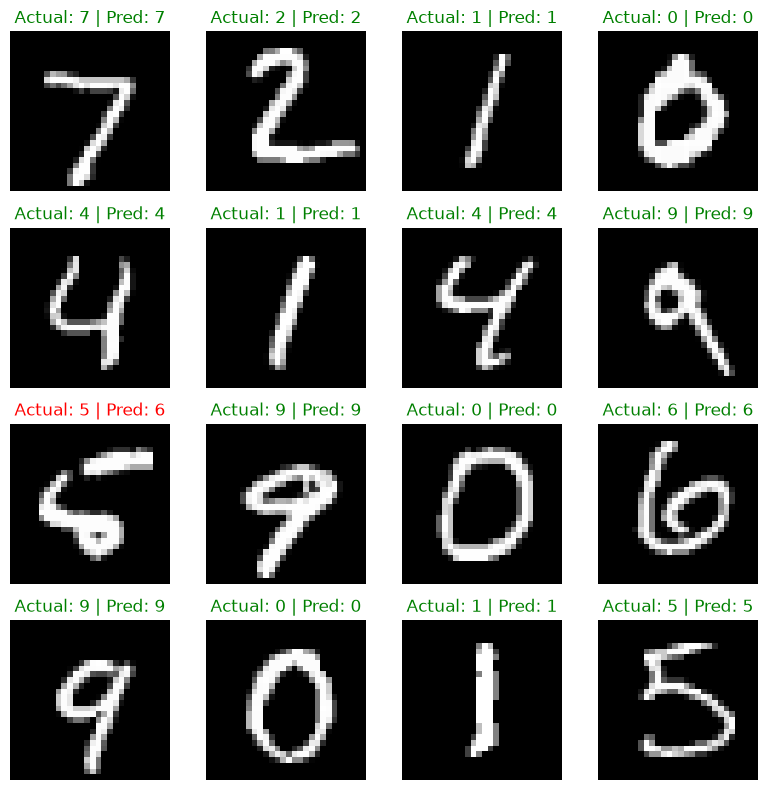

In [25]:
import matplotlib.pyplot as plt

cnn_model.eval()
images, labels = next(iter(test_loader))

with torch.no_grad():
    predictions = cnn_model(images).argmax(dim=1)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    actual = labels[i].item()
    predicted = predictions[i].item()

    color = "green" if actual == predicted else "red"
    ax.set_title(
        f"Actual: {actual} | Pred: {predicted}",
        color=color
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
print("MODEL COMPARISON")
print(f"Fully connected test accuracy: "
      f"{evaluate_model(baseline_model, test_loader):.2f}%")
print(f"CNN test accuracy: {cnn_accuracy:.2f}%")

MODEL COMPARISON
Fully connected test accuracy: 97.46%
CNN test accuracy: 98.93%


In [27]:
class LargerMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [28]:
torch.manual_seed(42)

larger_cnn = LargerMNISTCNN()

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    larger_cnn.parameters(),
    lr=0.001
)

larger_cnn_losses = []

for epoch in range(5):
    larger_cnn.train()
    total_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = larger_cnn(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    larger_cnn_losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {avg_loss:.4f}"
    )

Epoch 1/5 | Loss: 0.1887
Epoch 2/5 | Loss: 0.0504
Epoch 3/5 | Loss: 0.0342
Epoch 4/5 | Loss: 0.0257
Epoch 5/5 | Loss: 0.0203


In [29]:
larger_cnn_accuracy = evaluate_model(
    larger_cnn, test_loader
)

print(f"Original CNN: {cnn_accuracy:.2f}%")
print(f"Larger CNN:   {larger_cnn_accuracy:.2f}%")
print(
    f"Difference:   "
    f"{larger_cnn_accuracy - cnn_accuracy:+.2f} "
    "percentage points"
)

Original CNN: 98.93%
Larger CNN:   99.04%
Difference:   +0.11 percentage points


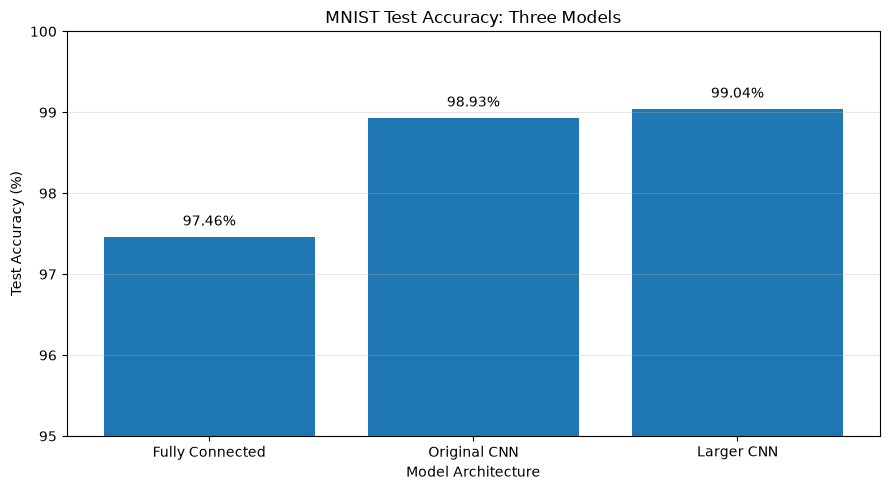

In [31]:
import matplotlib.pyplot as plt

# Test accuracy for each model
model_names = [
    "Fully Connected",
    "Original CNN",
    "Larger CNN"
]

accuracies = [
    evaluate_model(baseline_model, test_loader),
    cnn_accuracy,
    larger_cnn_accuracy
]

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(model_names, accuracies)

ax.set_ylabel("Test Accuracy (%)")
ax.set_xlabel("Model Architecture")
ax.set_title("MNIST Test Accuracy: Three Models")
ax.set_ylim(95, 100)

# Add percentage labels above each bar
for bar, accuracy in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
import torch
import torch.nn as nn

class BiggerMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # First convolution block: 28x28 -> 14x14
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block: 14x14 -> 7x7
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block: 7x7 -> 7x7
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


bigger_cnn = BiggerMNISTCNN()

print(bigger_cnn)

BiggerMNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [33]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(bigger_cnn.parameters(), lr=0.001)

bigger_cnn_losses = []

for epoch in range(5):
    bigger_cnn.train()
    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = bigger_cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    bigger_cnn_losses.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/5, "
        f"Loss: {epoch_loss:.4f}"
    )

Epoch 1/5, Loss: 0.1451
Epoch 2/5, Loss: 0.0393
Epoch 3/5, Loss: 0.0280
Epoch 4/5, Loss: 0.0200
Epoch 5/5, Loss: 0.0160


In [34]:
bigger_cnn_accuracy = evaluate_model(
    bigger_cnn,
    test_loader
)

print(f"Bigger CNN test accuracy: {bigger_cnn_accuracy:.2f}%")

Bigger CNN test accuracy: 99.33%


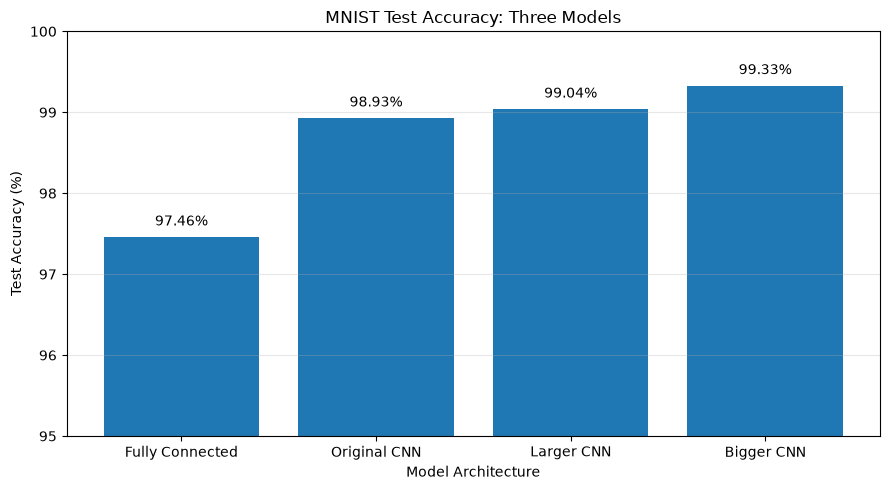

In [36]:
import matplotlib.pyplot as plt

# Test accuracy for each model
model_names = [
    "Fully Connected",
    "Original CNN",
    "Larger CNN",
    "Bigger CNN"
]

accuracies = [
    evaluate_model(baseline_model, test_loader),
    cnn_accuracy,
    larger_cnn_accuracy,
    bigger_cnn_accuracy
]

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(model_names, accuracies)

ax.set_ylabel("Test Accuracy (%)")
ax.set_xlabel("Model Architecture")
ax.set_title("MNIST Test Accuracy: Three Models")
ax.set_ylim(95, 100)

# Add percentage labels above each bar
for bar, accuracy in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Model                  Accuracy      Error    Accuracy Increase
----------------------------------------------------------------
Fully Connected          97.46%      2.54%                 Baseline
Original CNN             98.93%      1.07%  +1.47 percentage points
Larger CNN               99.04%      0.96%  +0.11 percentage points
Bigger CNN               99.33%      0.67%  +0.29 percentage points


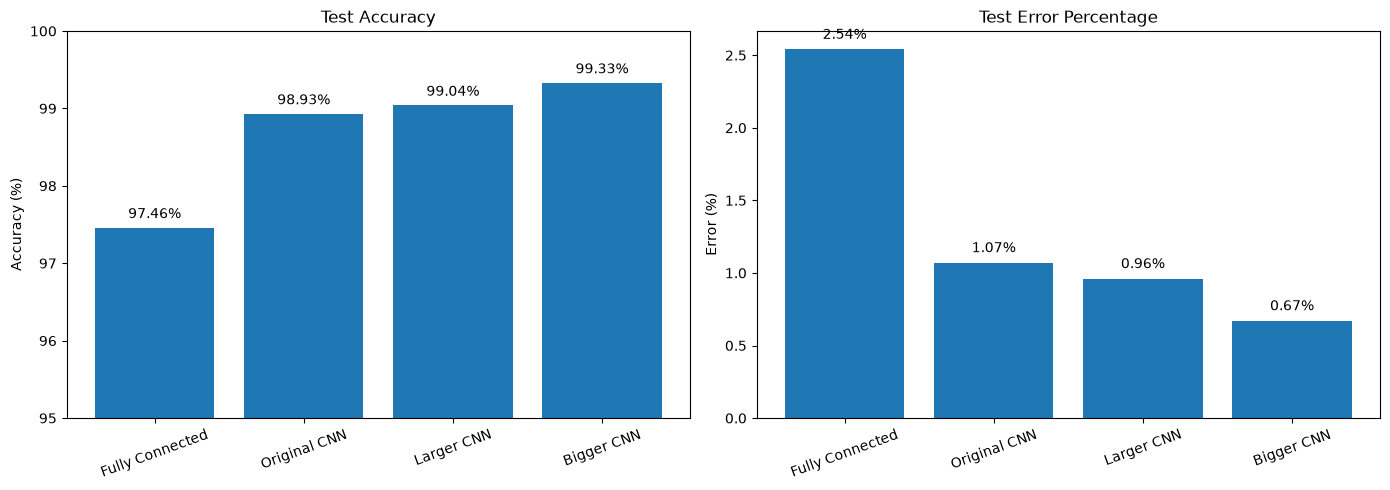

In [ ]:

import matplotlib.pyplot as plt

# Get test accuracy for all four models
model_names = [
    "Fully Connected",
    "Original CNN",
    "Larger CNN",
    "Bigger CNN"
]

accuracies = [
    evaluate_model(baseline_model, test_loader),
    cnn_accuracy,
    larger_cnn_accuracy,
    bigger_cnn_accuracy
]

# Calculate error percentage
errors = [100 - accuracy for accuracy in accuracies]

# Calculate improvement over the previous model
improvements = [0]  # No previous model for the first one

for i in range(1, len(accuracies)):
    improvements.append(accuracies[i] - accuracies[i - 1])

# Print a summary table
print(f"{'Model':<20} {'Accuracy':>10} {'Error':>10} {'Accuracy Increase':>20}")
print("-" * 64)

for i in range(len(model_names)):
    increase = "Baseline" if i == 0 else f"{improvements[i]:+.2f} percentage points"
    print(
        f"{model_names[i]:<20} "
        f"{accuracies[i]:>9.2f}% "
        f"{errors[i]:>9.2f}% "
        f"{increase:>24}"
    )

# Plot accuracy and error
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Print accuracy chart
bars1 = axes[0].bar(model_names, accuracies)
axes[0].set_title("Test Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(95, 100)
axes[0].tick_params(axis="x", rotation=20)

for bar, accuracy in zip(bars1, accuracies):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

# Print error chart
bars2 = axes[1].bar(model_names, errors)
axes[1].set_title("Test Error Percentage")
axes[1].set_ylabel("Error (%)")
axes[1].tick_params(axis="x", rotation=20)

for bar, error in zip(bars2, errors):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{error:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [41]:
models = {
    "Fully Connected": baseline_model,
    "Original CNN": cnn_model,
    "Larger CNN": larger_cnn,
    "Bigger CNN": bigger_cnn
}

results = {}

for name, model in models.items():
    accuracy = evaluate_model(model, test_loader)
    error = 100 - accuracy

    results[name] = {
        "Accuracy (%)": accuracy,
        "Error (%)": error
    }

    print(f"{name}:")
    print(f"  Test accuracy: {accuracy:.5f}%")
    print(f"  Test error:    {error:.5f}%")
    print()



Fully Connected:
  Test accuracy: 97.46000%
  Test error:    2.54000%

Original CNN:
  Test accuracy: 98.93000%
  Test error:    1.07000%

Larger CNN:
  Test accuracy: 99.04000%
  Test error:    0.96000%

Bigger CNN:
  Test accuracy: 99.33000%
  Test error:    0.67000%



In [48]:
import torch
import torch.nn as nn

class GiantMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # First convolution block: 28x28 -> 14x14
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block: 14x14 -> 7x7
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block: 7x7 -> 3x3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Fourth convolution block: 3x3 -> 1x1
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 2 * 2, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


giant_cnn = GiantMNISTCNN()

print(giant_cnn)

GiantMNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [49]:
giant_cnn = GiantMNISTCNN()

In [50]:
images, labels = next(iter(train_loader))

outputs = giant_cnn(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [51]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(giant_cnn.parameters(), lr=0.001)

giant_cnn_losses = []

for epoch in range(5):
    giant_cnn.train()
    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = giant_cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    giant_cnn_losses.append(epoch_loss)

    print(f"Epoch {epoch + 1}/5, Loss: {epoch_loss:.4f}")

Epoch 1/5, Loss: 0.1882
Epoch 2/5, Loss: 0.0471
Epoch 3/5, Loss: 0.0329
Epoch 4/5, Loss: 0.0255
Epoch 5/5, Loss: 0.0200


In [52]:
giant_cnn_accuracy = evaluate_model(giant_cnn, test_loader)

print(f"Accuracy: {giant_cnn_accuracy:.2f}%")
print(f"Error: {100 - giant_cnn_accuracy:.2f}%")

Accuracy: 99.06%
Error: 0.94%


Model                  Accuracy      Error    Accuracy Increase
----------------------------------------------------------------
Fully Connected          97.46%      2.54%                 Baseline
Original CNN             98.93%      1.07%  +1.47 percentage points
Larger CNN               99.04%      0.96%  +0.11 percentage points
Bigger CNN               99.33%      0.67%  +0.29 percentage points
Giant CNN                99.06%      0.94%  -0.27 percentage points


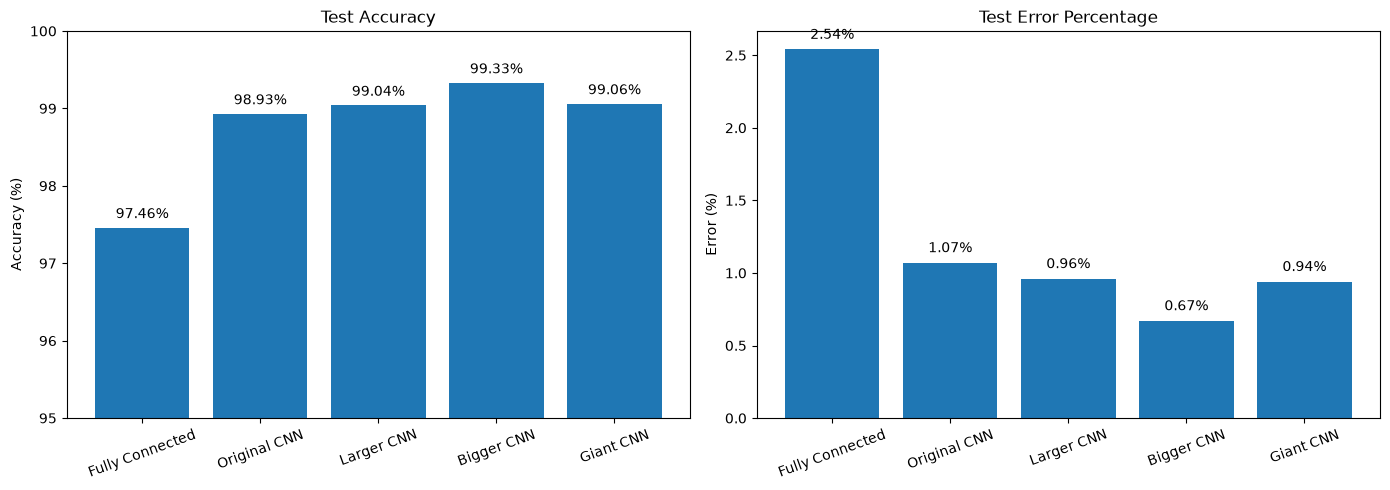

In [53]:
import matplotlib.pyplot as plt

# Get test accuracy for all four models
model_names = [
    "Fully Connected",
    "Original CNN",
    "Larger CNN",
    "Bigger CNN",
    "Giant CNN"
]

accuracies = [
    evaluate_model(baseline_model, test_loader),
    cnn_accuracy,
    larger_cnn_accuracy,
    bigger_cnn_accuracy,
    giant_cnn_accuracy
]

# Calculate error percentage
errors = [100 - accuracy for accuracy in accuracies]

# Calculate improvement over the previous model
improvements = [0]  # No previous model for the first one

for i in range(1, len(accuracies)):
    improvements.append(accuracies[i] - accuracies[i - 1])

# Print a summary table
print(f"{'Model':<20} {'Accuracy':>10} {'Error':>10} {'Accuracy Increase':>20}")
print("-" * 64)

for i in range(len(model_names)):
    increase = "Baseline" if i == 0 else f"{improvements[i]:+.2f} percentage points"
    print(
        f"{model_names[i]:<20} "
        f"{accuracies[i]:>9.2f}% "
        f"{errors[i]:>9.2f}% "
        f"{increase:>24}"
    )

# Plot accuracy and error
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Print accuracy chart
bars1 = axes[0].bar(model_names, accuracies)
axes[0].set_title("Test Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(95, 100)
axes[0].tick_params(axis="x", rotation=20)

for bar, accuracy in zip(bars1, accuracies):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

# Print error chart
bars2 = axes[1].bar(model_names, errors)
axes[1].set_title("Test Error Percentage")
axes[1].set_ylabel("Error (%)")
axes[1].tick_params(axis="x", rotation=20)

for bar, error in zip(bars2, errors):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{error:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [54]:
models = {
    "Fully Connected": baseline_model,
    "Original CNN": cnn_model,
    "Larger CNN": larger_cnn,
    "Bigger CNN": bigger_cnn,
    "Giant CNN (4 blocks)": giant_cnn
}

for name, model in models.items():
    accuracy = evaluate_model(model, test_loader)
    print(f"{name}: {accuracy:.2f}% accuracy")

Fully Connected: 97.46% accuracy
Original CNN: 98.93% accuracy
Larger CNN: 99.04% accuracy
Bigger CNN: 99.33% accuracy
Giant CNN (4 blocks): 99.06% accuracy


In [58]:
import sys; print(sys.executable)

c:\Users\macxh\miniconda3\envs\mnist-pytorch\python.exe


In [61]:
for name, model in models.items():
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name}: {parameters:,}")

Fully Connected: 101,770
Original CNN: 206,922
Larger CNN: 421,642
Bigger CNN: 1,701,130
Giant CNN (4 blocks): 520,330


In [62]:
for name, model in models.items():
    total = sum(p.numel() for p in model.parameters())
    print(f"{name}: {total:,} parameters")

Fully Connected: 101,770 parameters
Original CNN: 206,922 parameters
Larger CNN: 421,642 parameters
Bigger CNN: 1,701,130 parameters
Giant CNN (4 blocks): 520,330 parameters


In [64]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available to PyTorch")

PyTorch version: 2.14.1+cpu
CUDA available: False
GPU not available to PyTorch


In [65]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu
CUDA available: False
Selected device: cpu


In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
Selected device: cuda
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


In [2]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using: cuda
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


In [3]:
class GiantMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Convolutional layer 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolutional layer 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolutional layer 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolutional layer 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 2048),
            nn.ReLU(),
            nn.Linear(2048, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [4]:
giant_cnn = GiantMNISTCNN().to(device)

parameter_count = sum(
    p.numel() for p in giant_cnn.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")
print("Model device:", next(giant_cnn.parameters()).device)

Trainable parameters: 5,128,970
Model device: cuda:0


In [6]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 60000
Testing images: 10000


In [7]:
images, labels = next(iter(train_loader))
images = images.to(device)

outputs = giant_cnn(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [9]:
import time

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(giant_cnn.parameters(), lr=0.001)

giant_cnn_losses = []
start_time = time.time()

for epoch in range(5):
    giant_cnn.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = giant_cnn(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    giant_cnn_losses.append(avg_loss)

    print(f"Epoch {epoch + 1}/5, Loss: {avg_loss:.4f}")

giant_cnn_training_time = time.time() - start_time
print(f"Training time: {giant_cnn_training_time:.2f} seconds")

Epoch 1/5, Loss: 0.1536
Epoch 2/5, Loss: 0.0459
Epoch 3/5, Loss: 0.0336
Epoch 4/5, Loss: 0.0265
Epoch 5/5, Loss: 0.0205
Training time: 89.38 seconds


In [11]:
def evaluate_on_device(model, loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

In [12]:
giant_cnn_accuracy = evaluate_on_device(
    giant_cnn, test_loader, device
)

giant_cnn_errors = round(
    len(test_dataset) * (1 - giant_cnn_accuracy / 100)
)

print(f"Accuracy: {giant_cnn_accuracy:.2f}%")
print(f"Incorrect predictions: {giant_cnn_errors}")
print(f"Training time: {giant_cnn_training_time:.2f} seconds")

Accuracy: 98.54%
Incorrect predictions: 146
Training time: 89.38 seconds


In [14]:
for name in ["baseline_model", "cnn_model", "larger_cnn", "bigger_cnn", "giant_cnn"]:
    print(name, "exists" if name in globals() else "missing")

baseline_model missing
cnn_model missing
larger_cnn missing
bigger_cnn missing
giant_cnn exists


In [ ]:
class MNISTModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


# Model 2: Original CNN
class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Model 3: Larger CNN
class LargerMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Model 4: Bigger CNN
class BiggerMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


baseline_model = MNISTModel().to(device)
cnn_model = MNISTCNN().to(device)
larger_cnn = LargerMNISTCNN().to(device)
bigger_cnn = BiggerMNISTCNN().to(device)

print("All four models recreated.")

All four models recreated.


In [17]:
import torch
import torch.nn as nn
import time

def train_model(model, epochs=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    start = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {total_loss / len(train_loader):.4f}"
        )

    return time.time() - start


for name, model in [
    ("Fully Connected", baseline_model),
    ("Original CNN", cnn_model),
    ("Larger CNN", larger_cnn),
    ("Bigger CNN", bigger_cnn)
]:
    print(f"\nTraining {name}")
    train_model(model, epochs=5)


Training Fully Connected
Epoch 1/5, Loss: 0.3446
Epoch 2/5, Loss: 0.1553
Epoch 3/5, Loss: 0.1076
Epoch 4/5, Loss: 0.0803
Epoch 5/5, Loss: 0.0640

Training Original CNN
Epoch 1/5, Loss: 0.2135
Epoch 2/5, Loss: 0.0626
Epoch 3/5, Loss: 0.0447
Epoch 4/5, Loss: 0.0332
Epoch 5/5, Loss: 0.0260

Training Larger CNN
Epoch 1/5, Loss: 0.1768
Epoch 2/5, Loss: 0.0480
Epoch 3/5, Loss: 0.0342
Epoch 4/5, Loss: 0.0251
Epoch 5/5, Loss: 0.0198

Training Bigger CNN
Epoch 1/5, Loss: 0.1447
Epoch 2/5, Loss: 0.0421
Epoch 3/5, Loss: 0.0291
Epoch 4/5, Loss: 0.0207
Epoch 5/5, Loss: 0.0168


Fully Connected: 97.50%
Original CNN: 98.93%
Larger CNN: 98.91%
Bigger CNN: 99.29%
Giant CNN: 98.54%


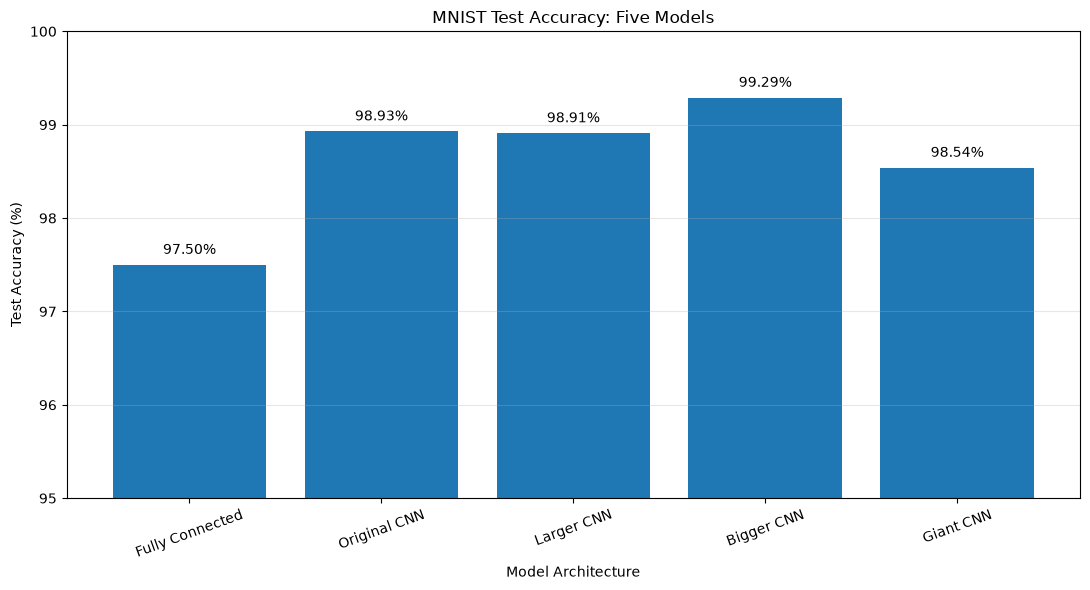

In [18]:
import matplotlib.pyplot as plt

models = {
    "Fully Connected": baseline_model,
    "Original CNN": cnn_model,
    "Larger CNN": larger_cnn,
    "Bigger CNN": bigger_cnn,
    "Giant CNN": giant_cnn
}

accuracies = []

for name, model in models.items():
    accuracy = evaluate_on_device(model, test_loader, device)
    accuracies.append(accuracy)
    print(f"{name}: {accuracy:.2f}%")

plt.figure(figsize=(11, 6))
bars = plt.bar(models.keys(), accuracies)

plt.xlabel("Model Architecture")
plt.ylabel("Test Accuracy (%)")
plt.title("MNIST Test Accuracy: Five Models")
plt.ylim(95, 100)
plt.xticks(rotation=20)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()